---
title: "Лекція 7. Аналіз чутливості, невизначеність і дизайн обчислювального експерименту"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

Лекція охоплює:

- *Тему 10. Аналіз чутливості та кількісне оцінювання невизначеності* -- 1 год;
- *Тему 11. Дизайн обчислювального експерименту* -- 1 год.

Наскрізна логіка:

$$
\text{credible model}
\rightarrow
\text{sensitivity}
\rightarrow
\text{uncertainty propagation}
\rightarrow
\text{experimental design}
\rightarrow
\text{evidence}
\rightarrow
\text{scientific inference}.
$$

Ключова теза:

$$
\boxed{
\text{simulation run}
\neq
\text{computational experiment}
\neq
\text{scientific inference}
}
$$
:::

# Вступ

У Лекції 6 ми сформували поняття *model credibility*, а в ЛР6 практично пройшли verification, validation, sensitivity та uncertainty propagation.

Тепер потрібно зробити наступний крок.

Модель стає науковим інструментом не тоді, коли її просто запускають, а тоді, коли за її допомогою ставлять *контрольований обчислювальний експеримент (computational experiment)*, пов'язаний із дослідницьким питанням.

Загальна логіка:

$$
RQ
\rightarrow
\text{factors}
\rightarrow
\text{design}
\rightarrow
\text{model runs}
\rightarrow
QoI
\rightarrow
\text{analysis}
\rightarrow
\text{scientific claim}.
$$

# Тема 10. Аналіз чутливості та кількісне оцінювання невизначеності

## 1. Навіщо аналізувати чутливість

Нехай model задає відображення

$$
Y=f(X_1,\ldots,X_k),
$$

де $Y$ -- Quantity of Interest, а $X_i$ -- parameters, initial conditions, inputs або scenario variables.

*Аналіз чутливості (Sensitivity Analysis, SA)* відповідає на питання:

> Як варіація входів пов'язана з варіацією output?

Це може бути потрібно для:

- розуміння mechanism;
- ranking parameters;
- simplification model;
- calibration planning;
- experimental design;
- uncertainty reduction;
- перевірки robustness conclusions [@saltelli2008].

## 2. Local sensitivity

Local sensitivity характеризує behavior поблизу конкретної точки

$$
\mathbf{x}_0.
$$

Для differentiable model:

$$
S_i^{local}
=
\left.
\frac{\partial Y}{\partial X_i}
\right|_{\mathbf{x}_0}.
$$

Для порівняння parameters різних scales корисна normalized sensitivity:

$$
S_i^{norm}
=
\frac{X_i}{Y}
\frac{\partial Y}{\partial X_i}.
$$

Інтерпретація:

$$
S_i^{norm}\approx2
$$

означає, що локально 1% зміни $X_i$ відповідає приблизно 2% зміни $Y$ за незмінних інших inputs.

## 3. Local sensitivity -- властивість точки, а не всієї моделі

Розглянемо

$$
Y=x_1x_2^2.
$$

Тоді

$$
\frac{\partial Y}{\partial x_1}=x_2^2,
$$

$$
\frac{\partial Y}{\partial x_2}=2x_1x_2.
$$

Normalized sensitivities:

$$
S_1^{norm}=1,
\qquad
S_2^{norm}=2.
$$

Для цієї спеціальної model вони сталі, але загалом

$$
S_i^{local}
=
S_i^{local}(\mathbf{x}_0).
$$

Отже, ranking parameters може змінюватися зі зміною regime.

## 4. One-at-a-time analysis і його межі

Поширений підхід:

1. fix baseline;
2. змінити $X_1$;
3. повернути baseline;
4. змінити $X_2$;
5. повторити для інших inputs.

Це *one-factor-at-a-time (OFAT)*.

Перевага -- простота.

Недолік -- interactions можуть залишитися невидимими.

Якщо

$$
Y=X_1X_2,
$$

ефект $X_1$ залежить від рівня $X_2$.

Тому:

$$
\text{OFAT}
\not\Rightarrow
\text{global understanding}.
$$

## 5. Global sensitivity

*Глобальний аналіз чутливості (Global Sensitivity Analysis, GSA)* досліджує model у всьому заданому input domain.

Нехай inputs є uncertain variables:

$$
X_i\sim p_i(x).
$$

Тоді output також стає random variable:

$$
Y=f(\mathbf X).
$$

Для variance-based SA аналізуємо:

$$
\operatorname{Var}(Y).
$$

Ідея -- визначити, яка частина output variance пов'язана з окремими inputs та їх interactions [@saltelli2008].

## 6. Sobol decomposition -- концептуальна основа

За відповідних assumptions model можна подати як

$$
f(\mathbf X)
=
f_0
+
\sum_i f_i(X_i)
+
\sum_{i<j}f_{ij}(X_i,X_j)
+\cdots.
$$

Тоді output variance:

$$
V(Y)
=
\sum_i V_i
+
\sum_{i<j}V_{ij}
+\cdots.
$$

*First-order Sobol index*:

$$
S_i
=
\frac{V_i}{V(Y)}
=
\frac{
\operatorname{Var}_{X_i}
\left[
E(Y\mid X_i)
\right]
}{
V(Y)
}.
$$

Він характеризує main effect input $X_i$.

## 7. Total-order Sobol index

*Total-order index* $S_{T_i}$ враховує main effect $X_i$ та всі interactions, у яких він бере участь.

Концептуально:

$$
S_{T_i}
=
1-
\frac{
\operatorname{Var}_{X_{\sim i}}
\left[
E(Y\mid X_{\sim i})
\right]
}{
V(Y)
}.
$$

Якщо

$$
S_{T_i}-S_i
$$

велике, input істотно бере участь у interactions.

Отже:

$$
S_i
\approx
\text{main effect},
$$

$$
S_{T_i}
\approx
\text{all effects involving }X_i.
$$

## 8. Простий приклад interaction

Нехай

$$
Y=X_1+X_2+2X_1X_2.
$$

Останній term

$$
2X_1X_2
$$

створює interaction.

Ефект $X_1$:

$$
\frac{\partial Y}{\partial X_1}
=
1+2X_2.
$$

Тобто він залежить від $X_2$.

Саме такі ситуації пояснюють, чому глобальні methods потрібні для nonlinear complex models.

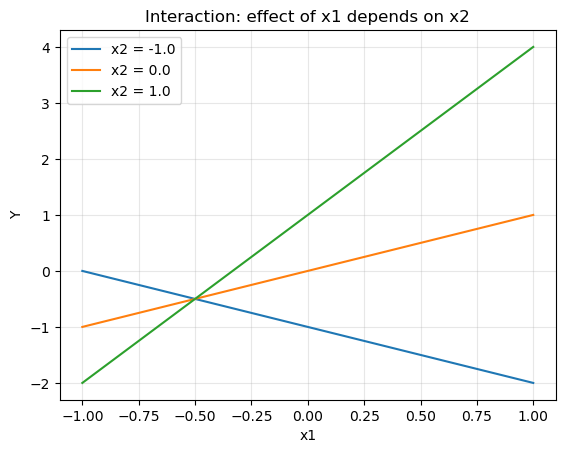

In [5]:
import numpy as np
import matplotlib.pyplot as plt

x1 = np.linspace(-1.0, 1.0, 200)

for x2 in [-1.0, 0.0, 1.0]:
    y = x1 + x2 + 2 * x1 * x2
    plt.plot(
        x1,
        y,
        label=f"x2 = {x2:.1f}"
    )

plt.xlabel("x1")
plt.ylabel("Y")
plt.title("Interaction: effect of x1 depends on x2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 9. Sensitivity analysis не дорівнює UQ

Ці два завдання пов'язані, але різні.

### Sensitivity Analysis

$$
\text{Which inputs drive changes in }Y?
$$

### Uncertainty Quantification

$$
\text{How uncertain is }Y?
$$

Input може бути:

- highly sensitive, але майже точно відомим;
- weakly sensitive, але дуже uncertain;
- sensitive лише через interactions.

Тому priority для подальшого дослідження визначається не sensitivity окремо.

## 10. Джерела невизначеності

У складній моделі uncertainty може походити з:

1. data;
2. parameters;
3. initial conditions;
4. external forcing;
5. stochastic mechanisms;
6. numerical approximation;
7. model structure;
8. assumptions;
9. scenarios.

Зручно розрізняти:

- *алеаторну невизначеність (aleatoric uncertainty)* -- intrinsic variability;
- *епістемічну невизначеність (epistemic uncertainty)* -- неповнота знання.

Але це distinction залежить від рівня опису і дослідницького контексту [@smith2024].

## 11. Uncertainty propagation

Нехай

$$
\mathbf X\sim p(\mathbf x).
$$

Тоді model індукує distribution output:

$$
Y=f(\mathbf X).
$$

Формально:

$$
p_Y(y)
=
\int
\delta
\left(
y-f(\mathbf x)
\right)
p_{\mathbf X}(\mathbf x)
d\mathbf x.
$$

Для складних computational models цей integral зазвичай не обчислюють аналітично.

Тому застосовують sampling methods, зокрема Monte Carlo [@smith2024].

## 12. Monte Carlo propagation

Генеруємо

$$
\mathbf X^{(m)}
\sim
p(\mathbf X),
\qquad
m=1,\ldots,M,
$$

і обчислюємо

$$
Y^{(m)}
=
f
\left(
\mathbf X^{(m)}
\right).
$$

Отриманий ensemble дозволяє оцінювати:

- mean;
- median;
- variance;
- quantiles;
- threshold probabilities;
- uncertainty intervals.

Важливо:

$$
\text{output uncertainty}
\text{ залежить від }
\text{input uncertainty model}.
$$

## 13. Uncertainty budget

Результат UQ потрібно супроводжувати *бюджетом невизначеності (uncertainty budget)*.

| Source | Representation | Propagated? | Evidence |
|---|---|---:|---|
| parameter uncertainty | distribution | yes/no | calibration |
| initial state | distribution/range | yes/no | measurements |
| stochastic dynamics | random process | yes/no | mechanism |
| numerical error | error estimate | yes/no | verification |
| model form | alternatives/discrepancy | yes/no | validation |
| scenario | scenario set | yes/no | research design |

Якщо source не включено, uncertainty interval його не відображає.

## 14. Robustness of conclusions

У багатьох PhD-дослідженнях важливішим є не точне значення $Y$, а stability scientific conclusion.

Нехай claim:

$$
C:
Y_A>Y_B.
$$

Тоді robustness можна досліджувати як

$$
P(Y_A>Y_B)
$$

за uncertainty inputs.

Отже, UQ може оцінювати uncertainty не лише prediction, а й *наукового висновку*.

## 15. Від sensitivity до нового experiment

Припустімо, GSA показав:

$$
S_{T_1}\gg S_{T_2},S_{T_3}.
$$

Це може означати:

- $X_1$ варто точніше вимірювати;
- для $X_1$ потрібен щільніший experimental design;
- $X_2,X_3$ можна fix у певному context;
- model reduction може бути можливою.

Тобто sensitivity analysis не завершує дослідження.

Він може *проєктувати наступний computational або empirical experiment*.

# Тема 11. Дизайн обчислювального експерименту

## 16. Що таке обчислювальний експеримент

*Обчислювальний експеримент (computational experiment)* -- систематично спроєктована серія model runs, призначена для відповіді на research question або перевірки hypothesis.

Важливо:

$$
\text{many simulations}
\neq
\text{designed experiment}.
$$

Не кількість runs робить experiment науковим.

Потрібні:

- RQ;
- factors;
- levels / distributions;
- controls;
- response / QoI;
- replication;
- analysis plan;
- inference rule.

## 17. Від Research Question до design

Приклад RQ:

> Як network topology та transmission intensity впливають на time to 50% activation?

Тоді:

- factor $A$ -- topology;
- factor $B$ -- transmission parameter $\beta$;
- response -- $T_{50}$;
- stochastic realization -- nuisance/random factor;
- $N$, initial seed rule, horizon -- controls.

Отже, RQ вже задає skeleton experiment.

## 18. Factors, levels, responses, controls

### Factor

Змінна, вплив якої досліджуємо.

### Level

Конкретне значення або category factor.

### Response

Output, за яким оцінюємо effect.

### Control variable

Величина, яку утримуємо сталою для comparability.

Схематично:

$$
Y
=
f
(
A,B,C;
Z
),
$$

де $A,B,C$ -- experimental factors, а $Z$ -- controlled conditions.

## 19. Design space

Нехай

$$
\mathbf x
=
(x_1,\ldots,x_k)
$$

-- vector factors.

*Простір дизайну (design space)*:

$$
\mathcal D
=
\mathcal X_1
\times
\cdots
\times
\mathcal X_k.
$$

Computational experiment вибирає subset

$$
\mathcal D_{exp}
\subseteq
\mathcal D.
$$

Питання дизайну:

> Які точки $\mathbf x$ потрібно обчислити, щоб отримати достатній evidence із прийнятною computational cost?

## 20. Parameter sweep -- корисний, але не достатній

Grid sweep:

$$
x_1\in\{a_1,\ldots,a_m\},
\qquad
x_2\in\{b_1,\ldots,b_n\}
$$

створює

$$
m\times n
$$

runs.

Це може бути хорошим design.

Але лише якщо зрозуміло:

- чому обрані ranges;
- чому обраний resolution;
- який response аналізується;
- які comparisons planned;
- як враховано stochasticity.

Без цього parameter sweep -- лише генерація output.

## 21. One-factor-at-a-time як experimental design

OFAT змінює один factor при fixed baseline.

Для двох factors:

$$
(A_0,B_0),
(A_1,B_0),
(A_0,B_1).
$$

Але точка

$$
(A_1,B_1)
$$

відсутня.

Тому interaction

$$
A\times B
$$

не можна оцінити.

Для nonlinear complex systems це суттєве обмеження.

## 22. Повний факторний експеримент

Для $k$ factors із двома levels маємо

$$
2^k
$$

combinations.

Для двох factors:

| Run | $A$ | $B$ |
|---:|---:|---:|
| 1 | $-1$ | $-1$ |
| 2 | $+1$ | $-1$ |
| 3 | $-1$ | $+1$ |
| 4 | $+1$ | $+1$ |

Цей design дозволяє оцінити:

- main effect $A$;
- main effect $B$;
- interaction $AB$.

## 23. Ручний приклад factorial effects

Нехай responses:

| $A$ | $B$ | $Y$ |
|---:|---:|---:|
| $-1$ | $-1$ | 10 |
| $+1$ | $-1$ | 14 |
| $-1$ | $+1$ | 12 |
| $+1$ | $+1$ | 24 |

Effect $A$:

$$
E_A
=
\frac{14+24}{2}
-
\frac{10+12}{2}
=
19-11
=
8.
$$

Effect $B$:

$$
E_B
=
\frac{12+24}{2}
-
\frac{10+14}{2}
=
18-12
=
6.
$$

Interaction можна побачити з conditional effects.

За $B=-1$:

$$
E_A^{B=-1}=14-10=4.
$$

За $B=+1$:

$$
E_A^{B=+1}=24-12=12.
$$

Отже, effect $A$ залежить від $B$.

In [6]:
import pandas as pd

factorial = pd.DataFrame({
    "A": [-1, 1, -1, 1],
    "B": [-1, -1, 1, 1],
    "Y": [10, 14, 12, 24]
})

effect_A = (
    factorial.loc[
        factorial["A"] == 1,
        "Y"
    ].mean()
    -
    factorial.loc[
        factorial["A"] == -1,
        "Y"
    ].mean()
)

effect_B = (
    factorial.loc[
        factorial["B"] == 1,
        "Y"
    ].mean()
    -
    factorial.loc[
        factorial["B"] == -1,
        "Y"
    ].mean()
)

print("Main effect A:", effect_A)
print("Main effect B:", effect_B)

Main effect A: 8.0
Main effect B: 6.0


## 24. Interaction plot

Якщо lines на interaction plot не паралельні, це вказує на interaction pattern.

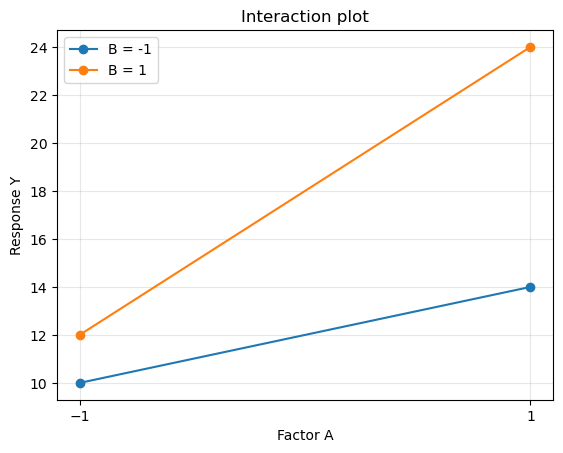

In [7]:
for b in [-1, 1]:
    subset = factorial[
        factorial["B"] == b
    ].sort_values("A")

    plt.plot(
        subset["A"],
        subset["Y"],
        marker="o",
        label=f"B = {b}"
    )

plt.xticks([-1, 1])
plt.xlabel("Factor A")
plt.ylabel("Response Y")
plt.title("Interaction plot")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 25. Stochastic model: один run не є response

Якщо model stochastic:

$$
Y
=
f(\mathbf x,\omega),
$$

де $\omega$ -- random realization.

Для одного design point $\mathbf x$ існує distribution:

$$
Y\mid\mathbf x.
$$

Тому потрібно replication:

$$
Y^{(1)}(\mathbf x),
\ldots,
Y^{(R)}(\mathbf x).
$$

Response може бути:

- $E[Y\mid\mathbf x]$;
- median;
- variance;
- quantile;
- probability of event.

## 26. Replication і Monte Carlo error

Для sample mean:

$$
\bar Y_R
=
\frac{1}{R}
\sum_{r=1}^{R}
Y^{(r)}.
$$

Standard error приблизно:

$$
SE(\bar Y_R)
=
\frac{s}{\sqrt R}.
$$

Щоб удвічі зменшити Monte Carlo standard error, приблизно потрібно вчетверо збільшити $R$.

Тому replication count має бути обґрунтованим, а не випадковим.

## 27. Common Random Numbers

Порівнюємо scenarios $A$ і $B$.

Якщо stochastic inputs генеруються незалежно:

$$
Y_A(\omega_A),
\qquad
Y_B(\omega_B),
$$

частина різниці може бути спричинена різними random realizations.

Іноді корисно застосувати *спільні випадкові числа (Common Random Numbers, CRN)*:

$$
Y_A(\omega),
\qquad
Y_B(\omega).
$$

Тоді pairwise difference

$$
D(\omega)
=
Y_A(\omega)-Y_B(\omega)
$$

може мати меншу variance.

CRN -- це experimental control, а не просто «однаковий seed».

## 28. Простий приклад CRN

Нехай:

$$
Y_A=10+\varepsilon,
$$

$$
Y_B=12+1.2\varepsilon.
$$

За common $\varepsilon$:

$$
Y_B-Y_A
=
2+0.2\varepsilon.
$$

За independent noises:

$$
Y_B-Y_A
=
2+1.2\varepsilon_B-\varepsilon_A.
$$

У другому випадку variance comparison значно більша.

In [8]:
rng = np.random.default_rng(42)
n = 5000

eps = rng.normal(0, 1, n)

diff_crn = (
    12 + 1.2 * eps
) - (
    10 + eps
)

eps_a = rng.normal(0, 1, n)
eps_b = rng.normal(0, 1, n)

diff_independent = (
    12 + 1.2 * eps_b
) - (
    10 + eps_a
)

print(
    "Variance with CRN:",
    round(
        np.var(diff_crn, ddof=1),
        4
    )
)

print(
    "Variance with independent random numbers:",
    round(
        np.var(diff_independent, ddof=1),
        4
    )
)

Variance with CRN: 0.04
Variance with independent random numbers: 2.4295


## 29. Scenario analysis

*Сценарний аналіз (scenario analysis)* досліджує qualitatively distinct configurations:

$$
S_1,S_2,\ldots,S_m.
$$

Scenario може задавати:

- policy;
- topology;
- environmental condition;
- mechanism;
- behavioral rule;
- external forcing.

Scenario не обов'язково має probability.

Тому:

$$
\text{scenario analysis}
\neq
\text{probabilistic UQ}.
$$

## 30. Ensemble experiments

*Ансамбль (ensemble)* -- множина model runs, що представляє variability через:

- parameter uncertainty;
- stochastic realizations;
- initial conditions;
- scenarios;
- alternative model structures.

Важливо документувати, *що саме варіюється*.

Інакше ensemble змішує різні uncertainty sources і стає важким для interpretation.

## 31. Competing models і competing hypotheses

Нехай існують дві hypotheses:

$$
H_1:
\text{outcome driven by mechanism A},
$$

$$
H_2:
\text{outcome driven by mechanism B}.
$$

Будуємо відповідні models:

$$
M_1,
\qquad
M_2.
$$

Тоді computational experiment має шукати regimes або QoI, де predictions models розрізняються.

Це сильніша логіка, ніж просто:

> «Ми запустили дві моделі та порівняли графіки».

## 32. Discriminating experiment

Хороший experiment може бути спроєктований так, щоб maximally distinguish competing explanations.

Нехай:

$$
\Delta(\mathbf x)
=
\left|
Q_{M_1}(\mathbf x)
-
Q_{M_2}(\mathbf x)
\right|.
$$

Тоді перспективним є regime:

$$
\mathbf x^*
=
\arg\max_{\mathbf x\in\mathcal D}
\Delta(\mathbf x).
$$

Це пов'язує computational experiment із плануванням empirical observation: вимірювати особливо цінно там, де hypotheses роблять різні predictions.

## 33. Exploration та confirmation

Корисно розділяти:

### Exploratory experiment

- шукаємо patterns;
- уточнюємо ranges;
- виявляємо regimes;
- формуємо hypotheses.

### Confirmatory experiment

- hypothesis сформульована до analysis;
- factors і QoI визначені;
- comparison planned;
- inference rule визначене.

Змішування exploration і confirmation збільшує ризик post hoc interpretation.

## 34. Computational budget

Нехай:

- $N_d$ -- кількість design points;
- $R$ -- replications;
- $C$ -- average cost одного run.

Тоді computational cost:

$$
C_{total}
\approx
N_dRC.
$$

Звідси виникає trade-off:

$$
\text{design coverage}
\leftrightarrow
\text{replication precision}
\leftrightarrow
\text{computational cost}.
$$

Для expensive models можуть знадобитися surrogate models, до яких повернемося в Темі 12.

## 35. Reproducibility experiment

Обчислювальний експеримент має бути відтворюваним.

Мінімально потрібно фіксувати:

- model version;
- code version;
- parameter set;
- factor levels;
- random seeds / random-number policy;
- solver settings;
- environment;
- data version;
- preprocessing;
- QoI definitions;
- analysis code.

Тому experiment -- це не лише output files, а reproducible protocol.

## 36. Experimental protocol

Для PhD-рівня корисно оформлювати protocol до запуску experiment.

| Поле | Зміст |
|---|---|
| Research Question | що перевіряємо? |
| Hypothesis | який effect очікуємо? |
| Model version | що саме запускаємо? |
| Factors | що варіюємо? |
| Levels / distributions | у яких межах? |
| Controls | що утримуємо сталим? |
| QoI | що вимірюємо? |
| Replications | скільки і чому? |
| Randomization / CRN | як працюємо зі stochasticity? |
| Analysis plan | як оцінюємо effect? |
| Inference rule | який claim дозволений? |
| Limitations | що experiment не перевіряє? |

## 37. Від output до scientific inference

Нехай experiment дав

$$
\hat{\Delta}
=
\bar Y_A-\bar Y_B.
$$

Саме число $\hat{\Delta}$ ще не є scientific conclusion.

Потрібно запитати:

1. чи effect robust до uncertainty?
2. чи не пояснюється він uncontrolled factor?
3. чи достатня replication?
4. чи знаходиться experiment у validated domain?
5. чи не залежить conclusion від одного model assumption?
6. чи підтримують competing models інше explanation?

Отже:

$$
\text{output}
+
\text{design logic}
+
\text{credibility evidence}
\rightarrow
\text{bounded inference}.
$$

## 38. Типові помилки computational experiment

### Помилка 1. Sweep без RQ

«Переберемо всі parameters і подивимося».

### Помилка 2. Один stochastic run

Random realization видається за system behavior.

### Помилка 3. Зміна кількох factors без control

Неможливо визначити source effect.

### Помилка 4. Ignoring interactions

OFAT використовується для strongly nonlinear system.

### Помилка 5. Cherry-picking

Показуються лише scenarios, що підтримують очікуваний claim.

### Помилка 6. Extrapolation без credibility evidence

Experiment проводиться далеко поза validated domain.

### Помилка 7. Simulation output = reality

Model behavior безпосередньо інтерпретується як факт про реальну систему.

## 39. Наскрізний приклад: мережеве поширення

Research Question:

> Як topology та $\beta$ впливають на $T_{50}$?

Factors:

$$
A\in
\{
ER,WS,BA
\},
$$

$$
\beta
\in
\{
0.1,0.2,0.3
\}.
$$

Для кожної combination:

$$
R=200
$$

stochastic replications.

Response:

$$
T_{50}.
$$

Controls:

- $N$;
- mean degree approximately matched;
- initial-source selection rule;
- simulation horizon.

Це вже experiment design, а не просто запуск network model.

## 40. Що можна стверджувати після такого experiment

Коректний bounded claim:

> За досліджених network classes, заданих $\beta$, однакового правила initial condition та визначеного stochastic process topology асоціюється з відмінностями distribution $T_{50}$.

Некоректний надмірний claim:

> Scale-free networks завжди поширюють інформацію швидше.

Другий висновок виходить далеко за design space та evidence.

## 41. Зв'язок із ЛР7

Наступна лабораторна робота має нормативну назву:

*«Лабораторна робота 7. Дизайн обчислювального експерименту та побудова hybrid/data-driven моделі».*

Вона поєднає дві лінії:

$$
\text{Model Credibility Report v0.6}
\rightarrow
\text{Experimental Protocol}
\rightarrow
\text{designed computational experiment}
$$

та

$$
\text{mechanistic model}
+
\text{data}
\rightarrow
\text{hybrid/data-driven model}.
$$

Отже, experiment design стане способом не лише дослідити model, а й порівняти alternative model formulations.

# 42. Підсумкова схема

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Research<br/>Question") --> B("Factors +<br/>uncertainties")
 B --> C("Sensitivity<br/>analysis")
 C --> D("Experimental<br/>design")
 D --> E("Model<br/>ensemble")
 E --> F("QoI +<br/>effects")
 F --> G("Uncertainty +<br/>robustness")
 G --> H("Bounded scientific<br/>inference")
```

# Контрольні запитання

1. Що таке sensitivity analysis?
2. Що таке local sensitivity?
3. Для чого використовується normalized sensitivity?
4. Чому local sensitivity залежить від operating point?
5. Які обмеження має OFAT?
6. Що таке global sensitivity analysis?
7. Яка ідея variance-based sensitivity analysis?
8. Що характеризує first-order Sobol index?
9. Що характеризує total-order Sobol index?
10. Що означає різниця $S_{T_i}-S_i$?
11. Чим sensitivity analysis відрізняється від UQ?
12. Які основні джерела uncertainty у computational model?
13. Чим aleatoric uncertainty відрізняється від epistemic?
14. Що таке uncertainty propagation?
15. Як працює Monte Carlo propagation?
16. Що таке uncertainty budget?
17. Як оцінювати robustness scientific conclusion?
18. Як sensitivity analysis може впливати на наступний experiment?
19. Що таке computational experiment?
20. Чому багато simulation runs ще не утворюють designed experiment?
21. Що таке factor, level, response і control?
22. Що таке design space?
23. Коли parameter sweep є науково обґрунтованим?
24. Чому OFAT не дозволяє повноцінно досліджувати interactions?
25. Що таке full factorial design?
26. Що таке interaction effect?
27. Чому stochastic model потребує replications?
28. Як replication count пов'язаний із Monte Carlo error?
29. Що таке Common Random Numbers?
30. Чим scenario analysis відрізняється від probabilistic UQ?
31. Що таке ensemble experiment?
32. Як computational experiment може порівнювати competing hypotheses?
33. Що таке discriminating experiment?
34. Чим exploratory experiment відрізняється від confirmatory?
35. Як computational budget обмежує design?
36. Що має містити reproducible experimental protocol?
37. Чому simulation output не є автоматично scientific inference?
38. Які типові помилки дизайну computational experiments?
39. Як domain of validity обмежує interpretation experiment?
40. Що означає bounded scientific inference?

# Висновки

1. Sensitivity analysis визначає, як variation inputs пов'язана з variation QoI.
2. Local sensitivity характеризує neighborhood конкретного operating point.
3. Global sensitivity досліджує весь заданий input domain.
4. Sobol indices дозволяють розділяти main effects та interaction contributions.
5. Sensitivity analysis і UQ відповідають на різні, хоча й пов'язані, питання.
6. Uncertainty interval відображає лише ті uncertainty sources, які включено в uncertainty model.
7. Uncertainty budget робить межі UQ явними.
8. Robustness scientific conclusion може бути важливішою за точність одного point estimate.
9. Computational experiment починається з Research Question, а не з запуску code.
10. Factors, levels, controls і QoI мають бути визначені до interpretation results.
11. Parameter sweep є лише технікою sampling design space.
12. Factorial design дозволяє виявляти interactions.
13. Stochastic models потребують replication та контролю Monte Carlo variability.
14. Common Random Numbers можуть підвищувати precision scenario comparison.
15. Scenario analysis не слід ототожнювати з probabilistic UQ.
16. Competing models дозволяють перетворити simulation на перевірку alternative explanations.
17. Experimental design повинен враховувати model credibility та domain of validity.
18. Reproducibility є властивістю experimental protocol, а не лише code.
19. Scientific inference має бути обмежене фактичним design space та evidence.
20. Наступний крок -- використати designed experiment для порівняння knowledge-driven, data-driven та hybrid model formulations.

# Джерела та корисні ресурси

Використовується спільна накопичувальна бібліографічна база курсу `mmss-references.bib`.

- [SALib documentation](https://salib.readthedocs.io/)
- [SciPy documentation](https://docs.scipy.org/doc/scipy/)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [pandas documentation](https://pandas.pydata.org/docs/)
- [Matplotlib documentation](https://matplotlib.org/stable/)

# References